Handwritten Digit Recognition Classifier

In [28]:
# Import libraries

import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import mnist
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

#matplotlib for visualisation
import matplotlib.pyplot as plt


In [29]:
# Load data
(X_train,y_train), (X_test,y_test) = mnist.load_data()

print(X_train.shape)
print(y_train.shape)

(60000, 28, 28)
(60000,)


Text(0.5, 1.1, 'Label, image')

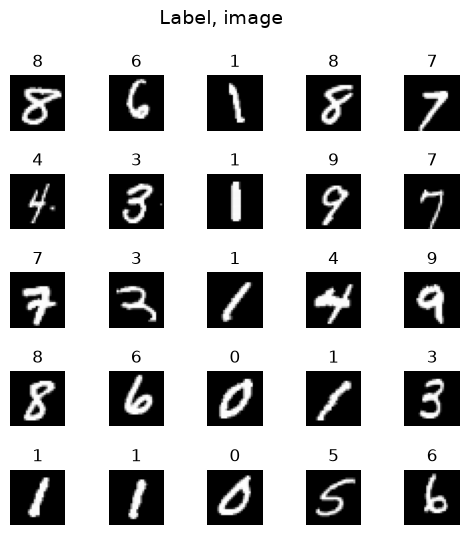

In [30]:
# Visualize image
#plt.imshow(X_train[2])

m = X_train.shape[0]
fig,axes = plt.subplots(5,5, figsize=(5,5))
fig.tight_layout(pad=0.5)

for i,ax in enumerate(axes.flat):
    random_idx = np.random.randint(m)
    X_reshaped = X_train[random_idx].reshape((28,28))
    ax.imshow(X_reshaped, cmap='gray')
    ax.set_axis_off()
    ax.set_title(y_train[random_idx])

fig.suptitle("Label, image", y=1.1, fontsize=14)


In [31]:
# Normalize the data

X_train = X_train/255.0
X_test = X_test/255.0

# Perform cross validation split

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,test_size=0.2,random_state=40,stratify=y_train)

print(X_train.shape)
print(X_val.shape)

(48000, 28, 28)
(12000, 28, 28)


In [32]:
# Building a Neural Network Classifier

tf.random.set_seed(1234)

model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation='relu',name='L1'),
    Dense(64,activation='relu',name='L2'),
    Dense(10,activation='linear',name='L3')
])

model.summary()



/opt/anaconda3/envs/tf_env/lib/python3.11/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L1 (Dense)                      │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2 (Dense)                      │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3 (Dense)                      │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
# Get layer weights
W1, b1 = model.get_layer('L1').get_weights()
W2, b2 = model.get_layer('L2').get_weights()
W3, b3 = model.get_layer('L3').get_weights()

print(W1.shape, b1.shape)
print(W2.shape, b2.shape)
print(W3.shape, b3.shape)

(784, 128) (128,)
(128, 64) (64,)
(64, 10) (10,)


In [35]:
# Define loss and optimizer

model.compile(
    loss = SparseCategoricalCrossentropy(from_logits=True),
    optimizer = Adam(learning_rate=0.0001),
    metrics=['accuracy']
)

history = model.fit(
    X_train,y_train,epochs=50,batch_size=32,validation_data=(X_val,y_val))

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9045 - loss: 0.3393 - val_accuracy: 0.9087 - val_loss: 0.3127
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9130 - loss: 0.3086 - val_accuracy: 0.9130 - val_loss: 0.2999
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9177 - loss: 0.2964 - val_accuracy: 0.9158 - val_loss: 0.2942
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9203 - loss: 0.2896 - val_accuracy: 0.9166 - val_loss: 0.2906
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9218 - loss: 0.2849 - val_accuracy: 0.9170 - val_loss: 0.2886
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9223 - loss: 0.2818 - val_accuracy: 0.9174 - val_loss: 0.2883
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9230 - loss: 0.2797 - val_accuracy: 0.9180 - val_loss: 0.2885
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9235 - loss: 0.2785 

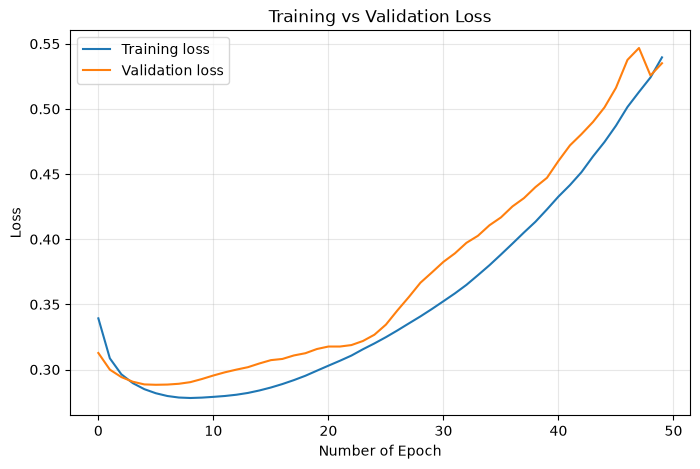

In [36]:
# Plot validation loss

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label="Training loss")
plt.plot(history.history['val_loss'], label="Validation loss")

plt.xlabel("Number of Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()

(28, 28)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
 Largest Prediction index: 3
 Predicting a Three. Probability vector: 
[[3.9570888e-19 4.3038259e-19 1.7116455e-09 9.9999940e-01 1.2867708e-11
  2.1251330e-09 7.8727676e-18 8.0330811e-11 5.9807343e-07 2.8357572e-10]]
Total sum of predictions: 1.000


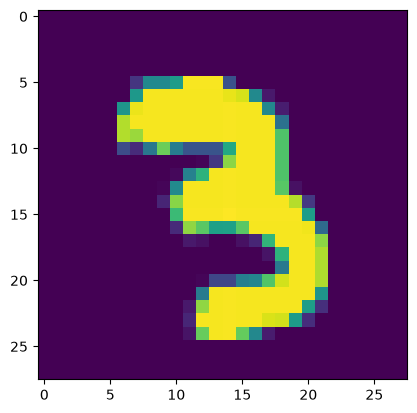

In [51]:
# Make predictions

plt.imshow(X_val[20]) # 3

expand_dims = X_val[20]
print(img_of_three.shape)

# Expanding the batch image size 

img_expanded = np.expand_dims(expand_dims,axis=0)

yhat = model.predict(img_expanded)

#print(yhat)
print(f" Largest Prediction index: {np.argmax(yhat)}")

# Printing probabilities
prediction_p = tf.nn.softmax(yhat)

print(f" Predicting a Three. Probability vector: \n{prediction_p}")
print(f"Total sum of predictions: {np.sum(prediction_p):0.3f}")

In [56]:
# Finding misclassifed digits

y_prob = model.predict(X_val)

y_pred = np.argmax(y_prob, axis=1)

misclassified = np.where(y_pred != y_val)[0]

print(f"No of Missclassifed images : ", len(misclassified))
print(f"Validation accuracy:", np.mean(y_pred == y_val))

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step 
No of Missclassifed images :  1368
Validation accuracy: 0.886


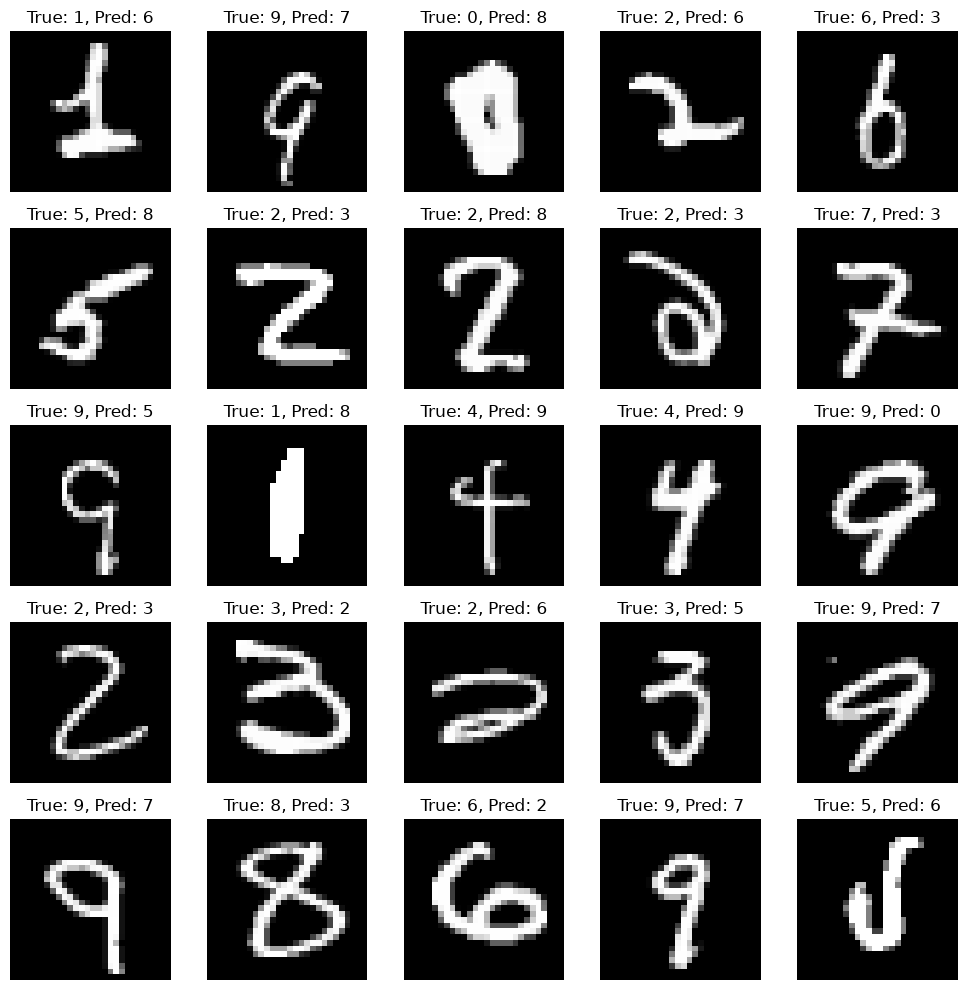

In [61]:
# Visualize upto 25 misclassifed images

n = min(25, len(misclassified))

fig, axes = plt.subplots(5,5, figsize=(10,10))

for i,ax in enumerate(axes.flat):
    idx = misclassified[i]
    ax.imshow(X_val[idx], cmap='gray')
    ax.set_title(f"True: {y_val[idx]}, Pred: {y_pred[idx]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0     0.9693    0.9578    0.9635      1185
           1     0.9665    0.9407    0.9534      1348
           2     0.8183    0.8423    0.8301      1192
           3     0.7767    0.9364    0.8491      1226
           4     0.9301    0.8998    0.9147      1168
           5     0.8404    0.8063    0.8230      1084
           6     0.9224    0.9139    0.9181      1184
           7     0.8655    0.9497    0.9056      1253
           8     0.8478    0.8094    0.8282      1170
           9     0.9550    0.7840    0.8611      1190

    accuracy                         0.8860     12000
   macro avg     0.8892    0.8840    0.8847     12000
weighted avg     0.8901    0.8860    0.8861     12000



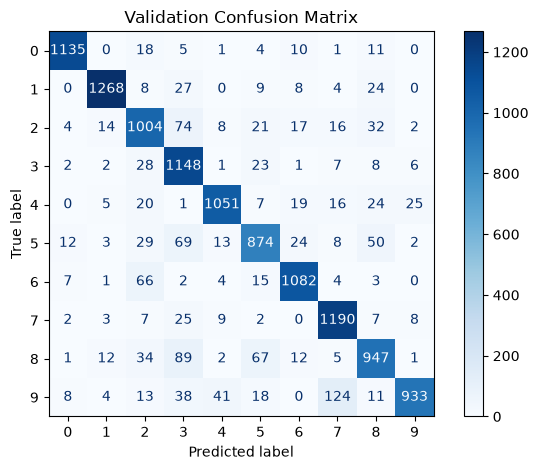

In [65]:
# Calculate Model metrics

from sklearn.metrics import classification_report,ConfusionMatrixDisplay

print(classification_report(y_val, y_pred, digits=4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    cmap='Blues'
)

plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [66]:
# Test Predictions

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0 )

print(f"Test loss: {test_loss}")
print(f"Test accuracy: {test_accuracy}")


Test loss: 0.5263878703117371
Test accuracy: 0.8873000144958496
